In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 9장 비지도 학습

## 9.1 군집

### 9.1.1 $k$-평균

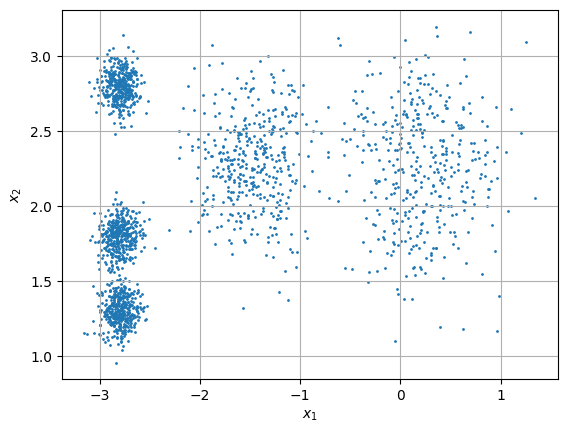

In [2]:
from sklearn.datasets import make_blobs

blob_centers = np.array([[0.2,  2.3], [-1.5 ,  2.3], [-2.8,  1.8], [-2.8,  2.8], [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std, random_state=7)

plt.scatter(X[:,0], X[:,1], s=1)
plt.grid()
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, n_init=20, random_state=42)
y_pred = kmeans.fit_predict(X)

In [4]:
y_pred

array([0, 4, 1, ..., 3, 1, 4], shape=(2000,), dtype=int32)

In [5]:
y_pred is kmeans.labels_

True

In [6]:
kmeans.cluster_centers_

array([[-2.80037642,  1.30082566],
       [ 0.20876306,  2.25551336],
       [-1.46679593,  2.28585348],
       [-2.79290307,  2.79641063],
       [-2.80389616,  1.80117999]])

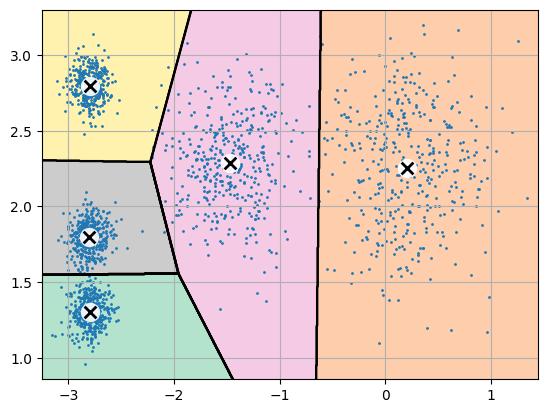

In [7]:
def plot_centroids(centroids, weights=None):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color='w', zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color='k', zorder=11, alpha=1)

def plot_decision_boundaries(cluster, X, show_centroids=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], 1000),
                         np.linspace(mins[1], maxs[1], 1000))
    Z = cluster.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), cmap='Pastel2')
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), colors='k')
    plt.scatter(X[:,0], X[:,1], s=1)

    if show_centroids:
        plot_centroids(cluster.cluster_centers_)
    
    plt.xlim(mins[0], maxs[0])
    plt.ylim(mins[1], maxs[1])
    plt.grid()

plot_decision_boundaries(kmeans, X)
plt.show()

In [8]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([1, 1, 3, 3], dtype=int32)

In [9]:
kmeans.transform(X_new).round(2)

array([[2.89, 0.33, 1.49, 2.9 , 2.81],
       [5.84, 2.8 , 4.48, 5.85, 5.81],
       [1.71, 3.29, 1.69, 0.29, 1.21],
       [1.22, 3.22, 1.55, 0.36, 0.73]])

#### 센트로이드 초기화 방법

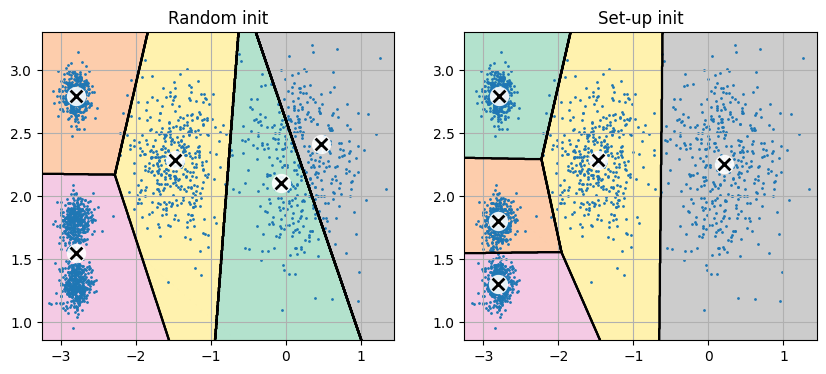

In [10]:
kmeans_rnd = KMeans(n_clusters=5, n_init=1, random_state=42)

good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans_init = KMeans(n_clusters=5, init=good_init, n_init=1, random_state=42)

kmeans_rnd.fit(X)
kmeans_init.fit(X)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('Random init')
plot_decision_boundaries(kmeans_rnd, X)
plt.subplot(1, 2, 2)
plt.title('Set-up init')
plot_decision_boundaries(kmeans_init, X)
plt.show()

In [11]:
kmeans_rnd.inertia_

224.07433122515727

In [12]:
kmeans_init.inertia_

211.5985372581684

In [13]:
kmeans_init.score(X)

-211.5985372581684

#### $k$-평균 속도 개선과 미니배치 $k$-평균

In [14]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42)
minibatch_kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:'k-means++' : selects initial cluster centroids using sampling based onan empirical probability distribution of the points' contribution to theoverall inertia. This technique speeds up convergence. The algorithmimplemented is ""greedy k-means++"". It differs from the vanilla k-means++by making several trials at each sampling step and choosing the best centroidamong them.'random': choose `n_clusters` observations (rows) at random from datafor the initial centroids.If an array is passed, it should be of shape (n_clusters, n_features)and gives the initial centers.If a callable is passed, it should take arguments X, n_clusters and arandom state and return an initialization.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=100Maximum number of iterations over the complete dataset beforestopping independently of any early stopping criterion heuristics.",100
,"batch_size batch_size: int, default=1024Size of the mini batches.For faster computations, you can set `batch_size > 256 * number_of_cores`to enable :ref:`parallelism `on all cores... versionchanged:: 1.0 `batch_size` default changed from 100 to 1024.",1024
,"verbose verbose: int, default=0Verbosity mode.",0
,"compute_labels compute_labels: bool, default=TrueCompute label assignment and inertia for the complete datasetonce the minibatch optimization has converged in fit.",True
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization andrandom reassignment. Use an int to make the randomness deterministic.See :term:`Glossary `.",42
,"tol tol: float, default=0.0Control early stopping based on the relative center changes asmeasured by a smoothed, variance-normalized of the mean centersquared position changes. This early stopping heuristics iscloser to the one used for the batch variant of the algorithmsbut induces a slight computational and memory overhead over theinertia heuristic.To disable convergence detection based on normalized centerchange, set tol to 0.0 (default).",0.0
,"max_no_improvement max_no_improvement: int, default=10Control early stopping based on the consecutive number of minibatches that does not yield an improvement on the smoothed inertia.To disable convergence detection based on inertia, setmax_no_improvement to None.",10
,"init_size init_size: int, default=NoneNumber of samples to randomly sample for speeding up theinitialization (sometimes at the expense of accuracy): theonly algorithm is initialized by running a batch KMeans on arandom subset of the data. This needs to be larger than n_clusters.If `None`, the heuristic is `init_size = 3 * batch_size` if`3 * batch_size < n_clusters`, else `init_size = 3 * n_clusters`.",None
,"n_init n_init: 'auto' or int, default=""auto""Number of random initializations that are tried.In contrast to KMeans, the algorithm is only run once, using the best ofthe `n_init` initializations as measured by inertia. Several runs arerecommended for sparse high-dimensional problems (see:ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:3 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'` in version.",'auto'


10/100
20/100
30/100
40/100
50/100
60/100
70/100
80/100
90/100
100/100


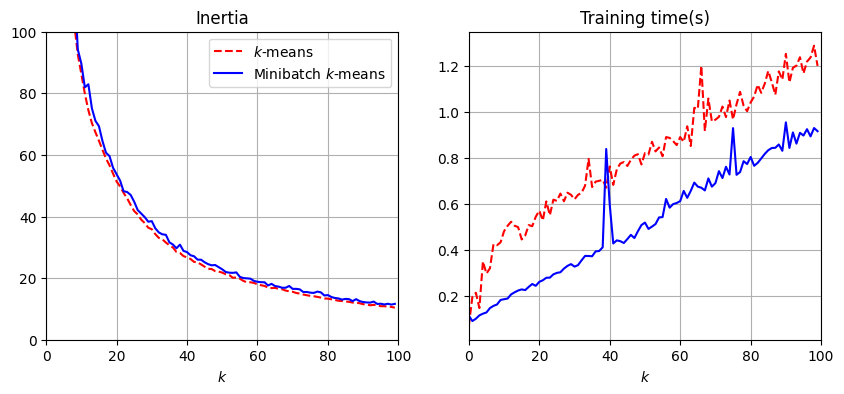

In [15]:
from timeit import timeit

max_k = 100
times = np.empty((max_k, 2))
inertias = np.empty((max_k, 2))
for k in range(1, max_k + 1):
    kmeans_ = KMeans(n_clusters=k, n_init=10, random_state=42)
    minibatch_kmeans = MiniBatchKMeans(n_clusters=k, n_init=10, random_state=42)

    times[k-1][0] = timeit('kmeans_.fit(X)', number=10, globals=globals())
    times[k-1][1] = timeit('minibatch_kmeans.fit(X)', number=10, globals=globals())

    inertias[k-1][0] = kmeans_.inertia_
    inertias[k-1][1] = minibatch_kmeans.inertia_

    if k % 10 == 0:
        print(f'{k}/{max_k}')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title('Inertia')
plt.plot(inertias[:,0], 'r--', label='$k$-means')
plt.plot(inertias[:,1], 'b-', label='Minibatch $k$-means')
plt.xlim(0, max_k)
plt.ylim(0, 100)
plt.xlabel('$k$')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.title('Training time(s)')
plt.plot(times[:, 0], 'r--')
plt.plot(times[:, 1], 'b-')
plt.xlim(0, max_k)
plt.grid()
plt.xlabel('$k$')

plt.show()

#### 최적의 클러스터 찾기

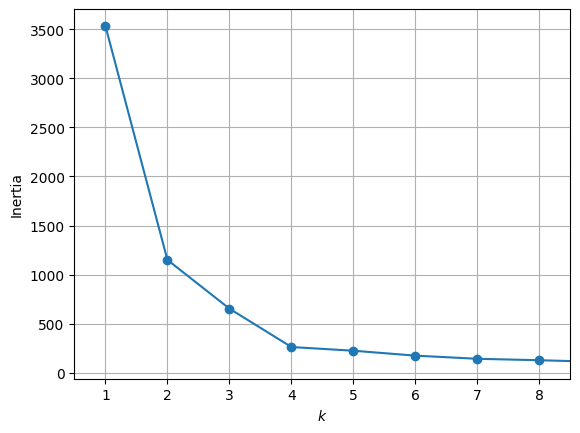

In [16]:
inertias = []
for k in range(1, 10):
    kmeans_ = KMeans(n_clusters=k, random_state=42)
    kmeans_.fit(X)
    inertias.append(kmeans_.inertia_)

plt.plot(range(1, 10), inertias, 'o-')
plt.xlim(0.5, 8.5)
plt.xlabel('$k$')
plt.ylabel('Inertia')
plt.grid()
plt.show()

In [17]:
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X)

silhouette_score(X, kmeans.labels_)

0.6267891051050734

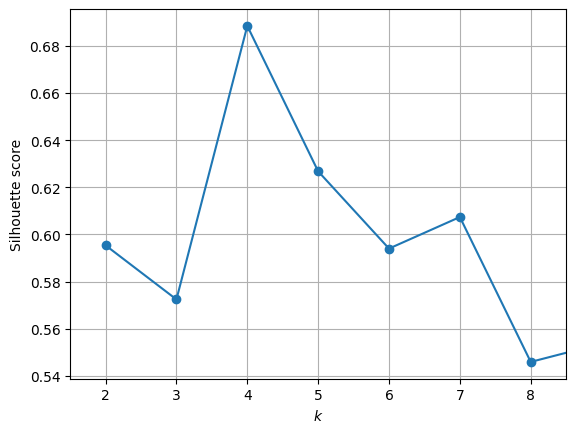

In [18]:
scores = []
for k in range(2, 10):
    kmeans_ = KMeans(n_clusters=k, random_state=42)
    kmeans_.fit(X)
    score = silhouette_score(X, kmeans_.labels_)
    scores.append(score)

plt.plot(range(2, 10), scores, 'o-')
plt.xlim(1.5, 8.5)
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.grid()
plt.show()

### 9.1.2 $k$-평균의 한계

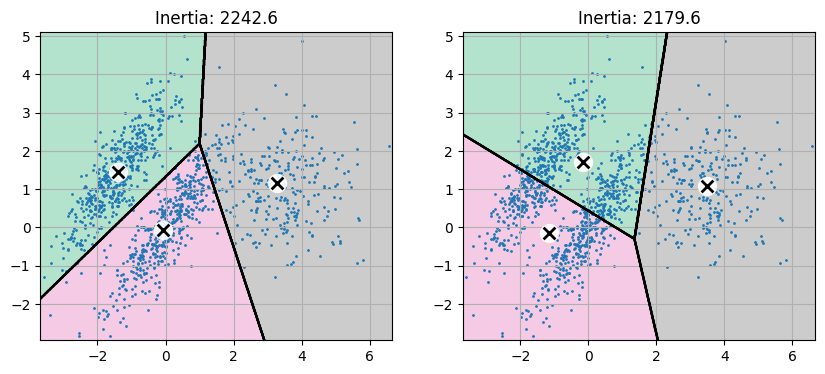

In [19]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

kmeans_good = KMeans(n_clusters=3, init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]),
                     n_init=1, random_state=42)
kmeans_bad = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title(f'Inertia: {kmeans_good.inertia_:.1f}')
plot_decision_boundaries(kmeans_good, X)
plt.subplot(1, 2, 2)
plt.title(f'Inertia: {kmeans_bad.inertia_:.1f}')
plot_decision_boundaries(kmeans_bad, X)
plt.show()

### 9.1.3 군집을 사용한 이미지 분할

In [20]:
import os
import urllib.request

filename = 'ladybug.png'
filepath = os.path.join(os.path.abspath(''), filename)

print('Downloading', filename)
url = f'https://github.com/ageron/handson-ml3/raw/main/images/unsupervised_learning/{filename}'
urllib.request.urlretrieve(url, filepath)
print('Complete!')

Complete!


In [21]:
import PIL

image = np.asarray(PIL.Image.open(filepath))
image.shape

(533, 800, 3)

In [22]:
X = image.reshape(-1, 3)
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

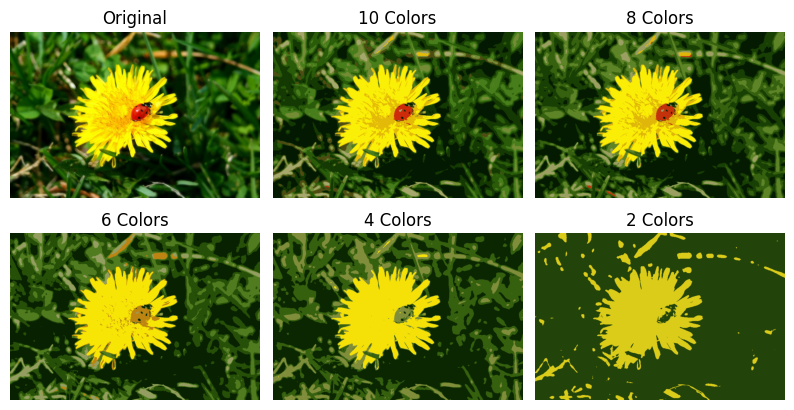

In [23]:
plt.figure(figsize=(10, 5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(2, 3, 1)
plt.title('Original')
plt.imshow(image)
plt.axis('off')

for i, k in enumerate([10, 8, 6, 4, 2]):
    kmeans_ = KMeans(n_clusters=k, random_state=42).fit(X)
    segmented_img = kmeans_.cluster_centers_[kmeans_.labels_]
    segmented_img = segmented_img.reshape(image.shape)
    plt.subplot(2, 3, i + 2)
    plt.title(f'{k} Colors')
    plt.imshow(segmented_img / 255)
    plt.axis('off')

plt.show()

### 9.1.4 군집을 사용한 준지도 학습

In [24]:
from sklearn.datasets import load_digits

X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

In [25]:
from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression(max_iter=10_000, random_state=42)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])

log_reg.score(X_test, y_test)

0.7581863979848866

In [26]:
k = 50
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)
representative_digit_idx = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train[representative_digit_idx]

In [27]:
X_digits_dist.shape

(1400, 50)

In [28]:
X_digits_dist[0]

array([39.2013243 , 51.61166593, 35.78092988, 44.28493339, 48.64385857,
       44.86465511, 43.30654472, 10.76074391, 48.30558974, 41.28401161,
       41.93956872, 42.98633504, 41.92168963, 44.04261648, 46.81608025,
       54.93901095, 38.76548078, 50.71102469, 40.6066079 , 42.38363099,
       46.57750837, 49.27563283, 41.12869024, 46.4091107 , 42.55083976,
       54.51497787, 18.57433293, 41.73051109, 41.24942795, 50.2961683 ,
       52.76570276, 55.87453876, 43.61459045, 49.48788301, 37.68089025,
       33.71680092, 37.67912946, 34.25329277, 39.48077357, 42.10499317,
       45.87102821, 46.70298587, 46.0271283 , 39.32629881, 46.60046352,
       44.2571964 , 42.06518266, 38.38114439, 50.23366329, 39.12819457])

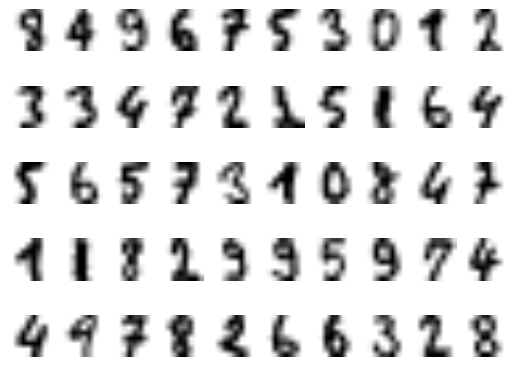

In [29]:
import math

for i, digit in enumerate(X_representative_digits):
    plt.subplot(math.ceil(k / 10), 10, i + 1)
    plt.imshow(digit.reshape(8, 8), cmap='binary', interpolation='bilinear')
    plt.axis('off')
plt.show()

In [30]:
y_representative_digits = y_train[representative_digit_idx]

y_representative_digits

array([8, 4, 9, 6, 7, 5, 3, 0, 1, 2, 3, 3, 4, 7, 2, 1, 5, 1, 6, 4, 5, 6,
       5, 7, 3, 1, 0, 8, 4, 7, 1, 1, 8, 2, 9, 9, 5, 9, 7, 4, 4, 9, 7, 8,
       2, 6, 6, 3, 2, 8])

In [31]:
log_reg.fit(X_representative_digits, y_representative_digits)

log_reg.score(X_test, y_test)

0.8387909319899244

In [32]:
y_train_propagated = np.empty(len(X_train), dtype=np.int64)
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_digits[i]

In [33]:
log_reg.fit(X_train, y_train_propagated)

log_reg.score(X_test, y_test)

0.8589420654911839

In [34]:
percentile_closet = 99

X_cluster_dist = X_digits_dist[np.arange(len(X_train)), kmeans.labels_]
for i in range(k):
    in_cluster = (kmeans.labels_ == i)
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_dist = np.percentile(cluster_dist, percentile_closet)
    above_cutoff = (X_cluster_dist > cutoff_dist)
    X_cluster_dist[in_cluster & above_cutoff] = -1

partially_propagated = (X_cluster_dist != -1)
X_train_partially_propagated = X_train[partially_propagated]
y_train_partially_propagated = y_train_propagated[partially_propagated]

In [35]:
from sklearn.metrics import accuracy_score

accuracy_score(y_train_propagated, y_train)

0.95

In [36]:
accuracy_score(y_train_partially_propagated, y_train[partially_propagated])

0.9548148148148148

In [37]:
X_train.shape

(1400, 64)

In [38]:
X_train_partially_propagated.shape

(1350, 64)

In [39]:
log_reg.fit(X_train_partially_propagated, y_train_partially_propagated)

log_reg.score(X_test, y_test)

0.8564231738035264

### 9.1.5 DBSCAN

In [40]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.05)

In [41]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.05
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [42]:
dbscan.labels_[:10]

array([0, 1, 2, 0, 3, 4, 0, 4, 0, 4])

In [43]:
dbscan.labels_.max()

np.int64(7)

In [44]:
len(dbscan.core_sample_indices_)

807

In [45]:
dbscan.core_sample_indices_[:10]

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 10])

In [46]:
dbscan.components_[:10]

array([[ 0.65439141,  0.66261631],
       [ 1.91003339,  0.26869659],
       [-0.02815053,  0.29985142],
       [ 0.46969166,  0.89318083],
       [-0.85001437,  0.53382887],
       [ 0.63410288, -0.46037889],
       [ 1.04546695,  0.17756072],
       [ 1.63115965, -0.22741379],
       [ 0.908217  ,  0.43021019],
       [ 1.29901773, -0.47694257]])

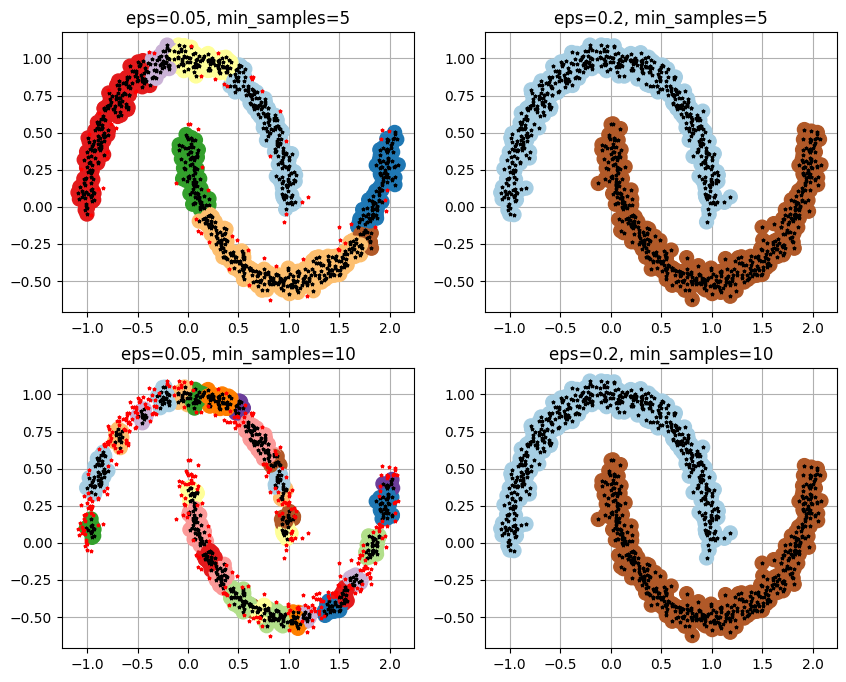

In [47]:
def plot_dbscan(dbscan, X, size=100):
    plt.scatter(X[dbscan.labels_!=-1][:,0], X[dbscan.labels_!=-1][:,1],
                c=dbscan.labels_[dbscan.labels_!=-1], s=size, cmap='Paired')
    plt.scatter(X[dbscan.labels_!=-1][:,0], X[dbscan.labels_!=-1][:,1], c='k', marker='*', s=5)
    plt.scatter(X[dbscan.labels_==-1][:,0], X[dbscan.labels_==-1][:,1], c='r', marker='*', s=5)
    plt.grid()
    plt.gca().set_axisbelow(True)

plt.figure(figsize=(10, 8))
for i, (eps, min_samples) in enumerate([(0.05, 5), (0.2, 5), (0.05, 10), (0.2, 10)]):
    dbscan_ = DBSCAN(eps=eps, min_samples=min_samples)
    dbscan_.fit(X)
    plt.subplot(2, 2, i + 1)
    plt.title(f'eps={eps}, min_samples={min_samples}')
    plot_dbscan(dbscan_, X)
plt.show()

In [48]:
from sklearn.neighbors import KNeighborsClassifier

dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X)

knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(dbscan.components_, dbscan.labels_[dbscan.core_sample_indices_])

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",50
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [49]:
X_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])

knn.predict(X_new)

array([0, 1, 0, 1])

In [50]:
knn.predict_proba(X_new)

array([[0.82, 0.18],
       [0.  , 1.  ],
       [0.84, 0.16],
       [0.  , 1.  ]])

In [51]:
y_dist, y_pred_idx = knn.kneighbors(X_new, n_neighbors=1)

In [52]:
y_dist

array([[0.36192005],
       [0.0230153 ],
       [0.05073835],
       [0.4860775 ]])

In [53]:
y_pred_idx

array([[422],
       [971],
       [511],
       [668]])

In [54]:
y_pred = dbscan.labels_[dbscan.core_sample_indices_][y_pred_idx]
y_pred

array([[0],
       [1],
       [0],
       [1]])

In [55]:
y_pred[y_dist > 0.2] = -1

y_pred.ravel()

array([-1,  1,  0, -1])

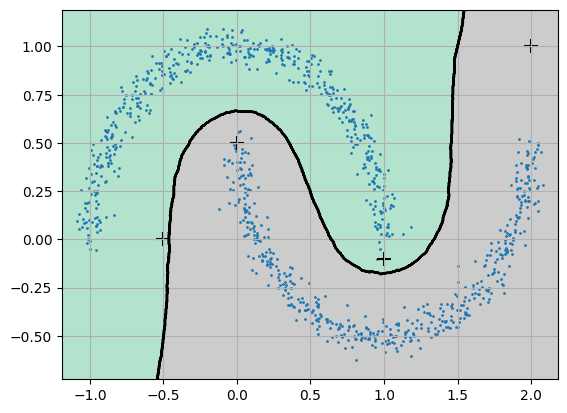

In [56]:
plot_decision_boundaries(knn, X, show_centroids=False)
plt.scatter(X_new[:,0], X_new[:,1], marker='+', c='k', s=100)
plt.show()

## 9.2 가우스 혼합

In [57]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

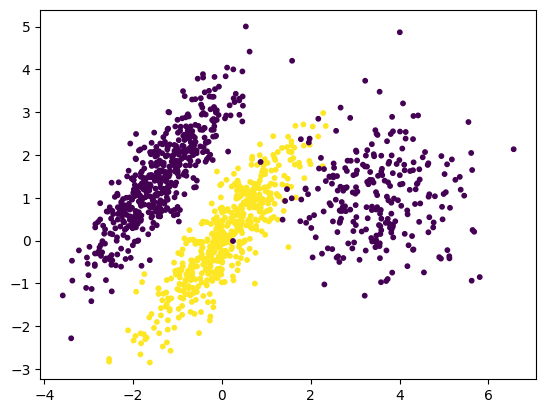

In [58]:
plt.scatter(X[:,0], X[:,1], c=y, s=10)
plt.show()

In [59]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=3, n_init=10, random_state=42)
gm.fit(X)

,"n_components n_components: int, default=1The number of mixture components.",3
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",10
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [60]:
gm.weights_

array([0.40005972, 0.20961444, 0.39032584])

In [61]:
gm.means_

array([[-1.40764129,  1.42712848],
       [ 3.39947665,  1.05931088],
       [ 0.05145113,  0.07534576]])

In [62]:
gm.covariances_

array([[[ 0.63478217,  0.72970097],
        [ 0.72970097,  1.16094925]],

       [[ 1.14740131, -0.03271106],
        [-0.03271106,  0.95498333]],

       [[ 0.68825143,  0.79617956],
        [ 0.79617956,  1.21242183]]])

In [63]:
gm.converged_

True

In [64]:
gm.n_iter_

4

In [65]:
gm.predict(X)

array([2, 2, 0, ..., 1, 1, 1], shape=(1250,))

In [66]:
gm.predict_proba(X).round(3)

array([[0.   , 0.023, 0.977],
       [0.001, 0.016, 0.983],
       [1.   , 0.   , 0.   ],
       ...,
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ]], shape=(1250, 3))

In [67]:
X_new, y_new = gm.sample(6)

In [68]:
X_new

array([[-2.32491052,  1.04752548],
       [-1.16654983,  1.62795173],
       [ 1.84860618,  2.07374016],
       [ 3.98304484,  1.49869936],
       [ 3.8163406 ,  0.53038367],
       [ 0.38079484, -0.56239369]])

In [69]:
y_new

array([0, 0, 1, 1, 1, 2])

In [70]:
gm.score_samples(X).round(2)

array([-2.61, -3.57, -3.33, ..., -3.51, -4.4 , -3.81], shape=(1250,))

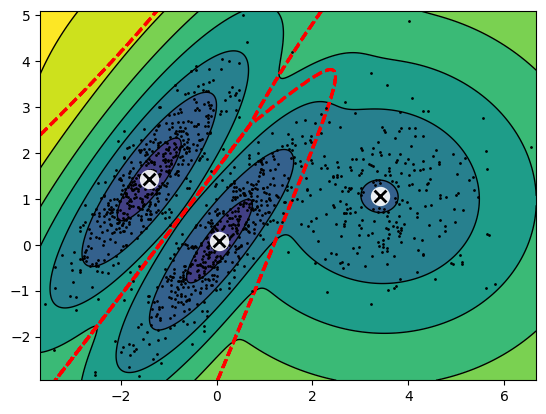

In [71]:
from matplotlib.colors import LogNorm

def plot_gaussian_mixture(clusterer, X):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], 1000),
                         np.linspace(mins[1], maxs[1], 1000))
    Z = -clusterer.score_samples(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z,
                 norm=LogNorm(vmin=1.0, vmax=30.0),
                 levels=np.logspace(0, 2, 12))
    plt.contour(xx, yy, Z,
                norm=LogNorm(vmin=1.0, vmax=30.0),
                levels=np.logspace(0, 2, 12),
                linewidths=1, colors='k')

    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contour(xx, yy, Z,
                linewidths=2, colors='r', linestyles='dashed')

    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)
    plot_centroids(clusterer.means_, clusterer.weights_)

plot_gaussian_mixture(gm, X)

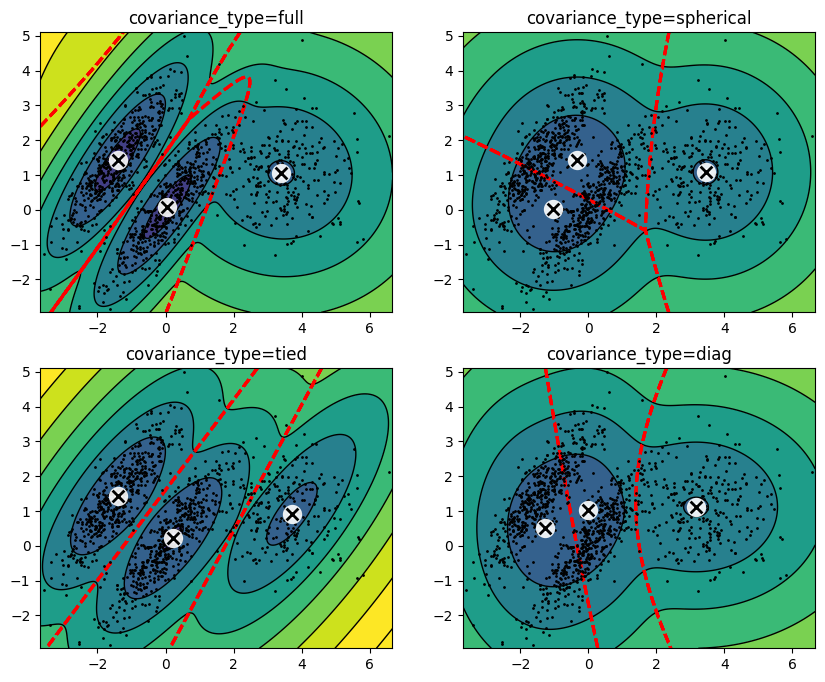

In [72]:
gm_spherical = GaussianMixture(n_components=3, covariance_type='spherical', n_init=10, random_state=42)
gm_tied = GaussianMixture(n_components=3, covariance_type='tied', n_init=10, random_state=42)
gm_diag = GaussianMixture(n_components=3, covariance_type='diag', n_init=10, random_state=42)

gm_spherical.fit(X)
gm_tied.fit(X)
gm_diag.fit(X)

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.title('covariance_type=full')
plot_gaussian_mixture(gm, X)
plt.subplot(2, 2, 2)
plt.title('covariance_type=spherical')
plot_gaussian_mixture(gm_spherical, X)
plt.subplot(2, 2, 3)
plt.title('covariance_type=tied')
plot_gaussian_mixture(gm_tied, X)
plt.subplot(2, 2, 4)
plt.title('covariance_type=diag')
plot_gaussian_mixture(gm_diag, X)
plt.show()

In [73]:
gm.covariances_

array([[[ 0.63478217,  0.72970097],
        [ 0.72970097,  1.16094925]],

       [[ 1.14740131, -0.03271106],
        [-0.03271106,  0.95498333]],

       [[ 0.68825143,  0.79617956],
        [ 0.79617956,  1.21242183]]])

In [74]:
gm_spherical.covariances_

array([1.13594643, 1.01596435, 1.11630807])

In [75]:
gm_tied.covariances_

array([[0.81598417, 0.74807911],
       [0.74807911, 1.20499105]])

In [76]:
gm_diag.covariances_

array([[0.77571234, 1.59300307],
       [0.65913713, 1.58523737],
       [1.52699364, 0.92948184]])

### 9.2.1 가우스 혼합을 사용한 이상치 탐지

In [77]:
densities = gm.score_samples(X)
density_threshold = np.percentile(densities, 2)
anomalies = X[densities < density_threshold]

anomalies

array([[ 0.74219223, -1.00445177],
       [-2.53940854, -2.76549965],
       [-1.74680316, -0.78385111],
       [ 0.53903026,  5.00244257],
       [-0.51480414, -2.16270124],
       [-1.79651788, -0.97031471],
       [-3.39408574, -2.28378778],
       [ 1.58082729,  4.20122873],
       [-2.06317379,  2.2670332 ],
       [-2.54004484, -2.8290338 ],
       [-1.93037427, -1.19447352],
       [-0.27124433, -1.86750177],
       [-1.93315582,  2.49030105],
       [ 5.80546094, -0.85297906],
       [ 5.68060531,  0.20598784],
       [ 3.55103259,  3.47752824],
       [ 5.5515503 ,  2.76962697],
       [ 4.00585006,  4.86701762],
       [ 3.22614554,  3.73445529],
       [ 5.61295857,  2.04675139],
       [ 5.62383575, -0.93780167],
       [ 2.30754386, -1.02494605],
       [ 6.56968319,  2.13386104],
       [ 3.21575068, -1.28763504],
       [ 4.07765947,  3.20474175]])

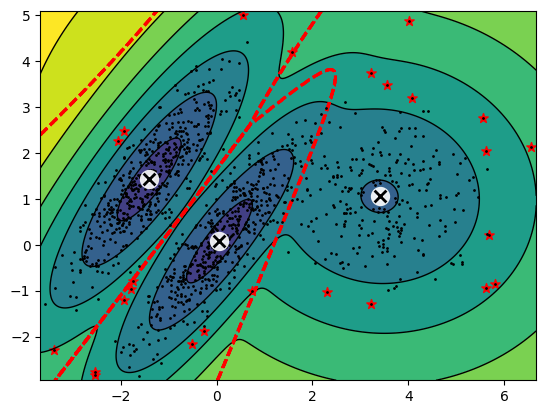

In [78]:
plot_gaussian_mixture(gm, X)
plt.scatter(anomalies[:,0], anomalies[:,1], marker='*', c='r', s=50)
plt.show()

### 9.2.2 클러스터 개수 선택

In [79]:
gm.bic(X)

8189.733705221636

In [80]:
gm.aic(X)

8102.508425106598

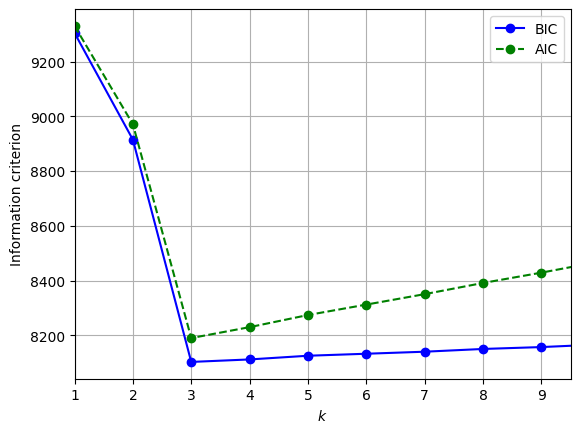

In [81]:
bics = []
aics = []
for k in range(1, 11):
    gm_ = GaussianMixture(n_components=k, n_init=10, random_state=42)
    gm_.fit(X)
    bics.append(gm_.bic(X))
    aics.append(gm_.aic(X))

plt.plot(range(1, 11), aics, 'b-o', label='BIC')
plt.plot(range(1, 11), bics, 'g--o', label='AIC')
plt.legend()
plt.grid()
plt.xlabel('$k$')
plt.ylabel('Information criterion')
plt.xlim(1, 9.5)
plt.show()

### 9.2.3 베이즈 가우스 혼합 모델

In [82]:
from sklearn.mixture import BayesianGaussianMixture

bgm = BayesianGaussianMixture(n_components=10, n_init=10, max_iter=150, random_state=42)
bgm.fit(X)
bgm.weights_.round(2)

array([0.4 , 0.21, 0.39, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

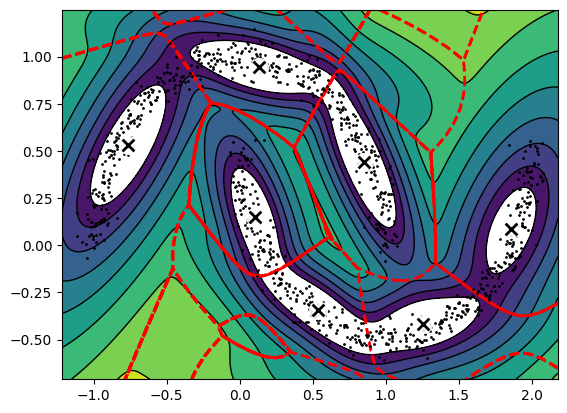

In [83]:
X_moon, y_moon = make_moons(n_samples=1000, noise=0.05)

bgm = BayesianGaussianMixture(n_components=10, n_init=10, max_iter=200, random_state=42)
bgm.fit(X_moon)

plot_gaussian_mixture(bgm, X_moon)
plt.show()

## 연습문제

### ⑩

In [84]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()
X, y = olivetti.data, olivetti.target

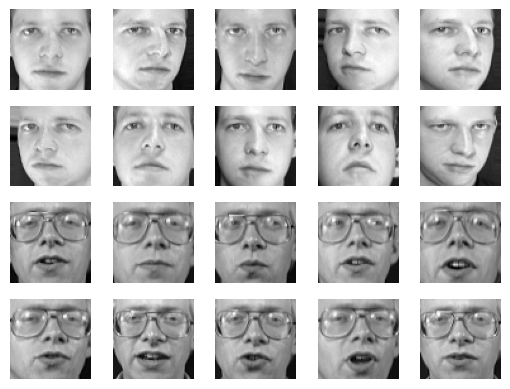

In [85]:
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X[i].reshape(64, 64), cmap='grey')
    plt.axis('off')
plt.show()

In [86]:
from sklearn.model_selection import StratifiedShuffleSplit

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=40, random_state=42)
train_valid_idx, test_idx = next(strat_split.split(X, y))
X_train_valid = X[train_valid_idx]
y_train_valid = y[train_valid_idx]
X_test = X[test_idx]
y_test = y[test_idx]

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=80, random_state=42)
train_idx, valid_idx = next(strat_split.split(X_train_valid, y_train_valid))
X_train = X[train_idx]
y_train = y[train_idx]
X_valid = X[valid_idx]
y_valid = y[valid_idx]

In [87]:
X_train.shape

(280, 4096)

In [88]:
X_valid.shape

(80, 4096)

In [89]:
X_test.shape

(40, 4096)

In [90]:
ks = range(10, 150, 5)

scores = []
inertias = []
for k in ks:
    kmeans_ = KMeans(n_clusters=k, random_state=42)
    kmeans_.fit(X_train)
    scores.append(silhouette_score(X_train, kmeans_.labels_))
    inertias.append(kmeans_.inertia_)

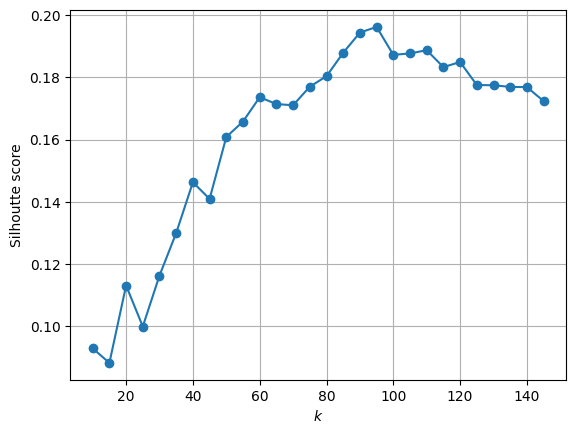

In [91]:
plt.plot(ks, scores, 'o-')
plt.xlabel('$k$')
plt.ylabel('Silhoutte score')
plt.grid()
plt.show()

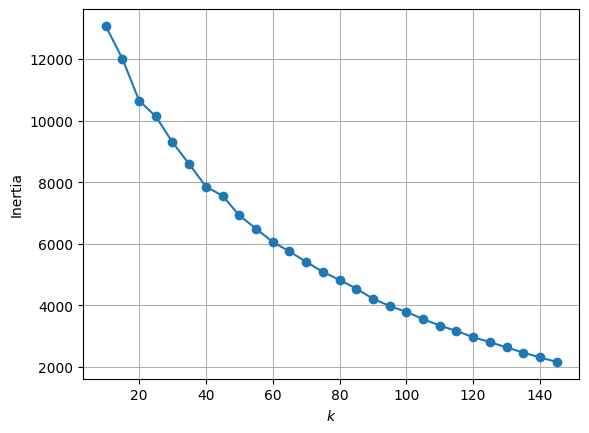

In [92]:
plt.plot(ks, inertias, 'o-')
plt.xlabel('$k$')
plt.ylabel('Inertia')
plt.grid()
plt.show()

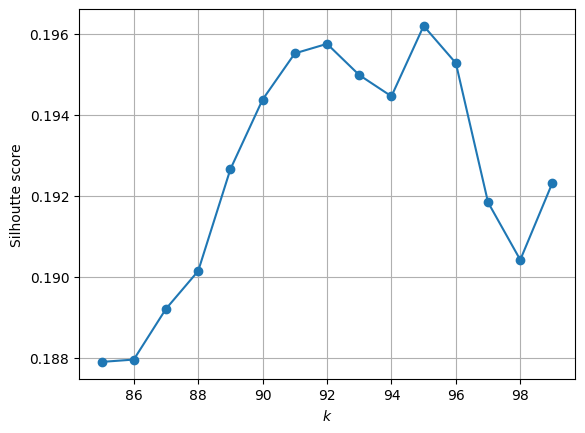

In [93]:
ks = range(85, 100)

scores = []
for k in ks:
    kmeans_ = KMeans(n_clusters=k, random_state=42)
    kmeans_.fit(X_train)
    scores.append(silhouette_score(X_train, kmeans_.labels_))

plt.plot(ks, scores, 'o-')
plt.xlabel('$k$')
plt.ylabel('Silhoutte score')
plt.grid()
plt.show()

In [94]:
best_k = ks[np.array(scores).argmax()]

best_k

95

Cluster 0


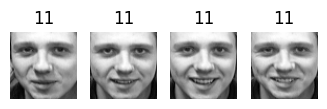

Cluster 1


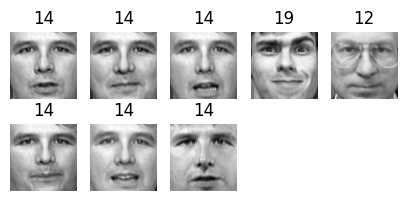

Cluster 2


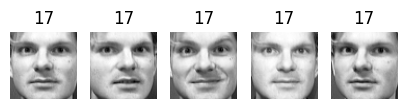

Cluster 3


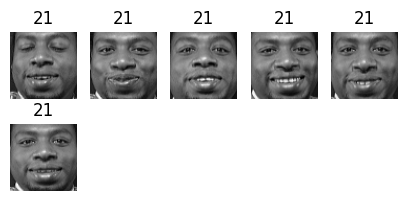

Cluster 4


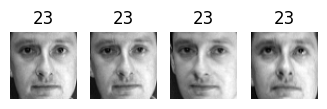

Cluster 5


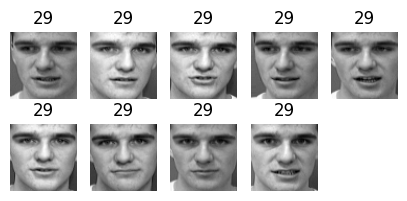

Cluster 6


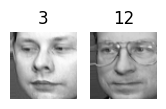

Cluster 7


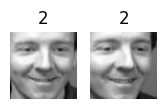

Cluster 8


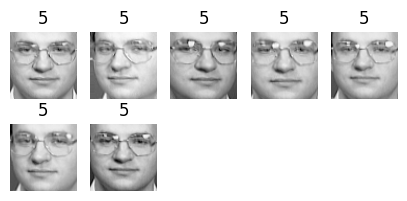

Cluster 9


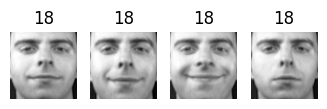

Cluster 10


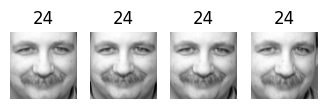

Cluster 11


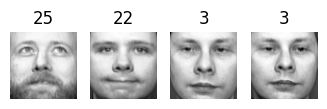

Cluster 12


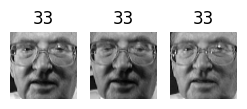

Cluster 13


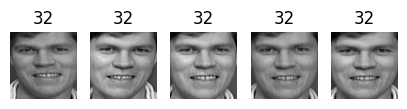

Cluster 14


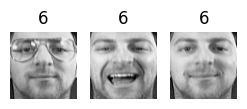

Cluster 15


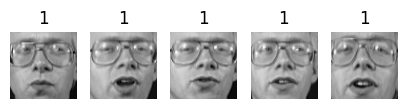

Cluster 16


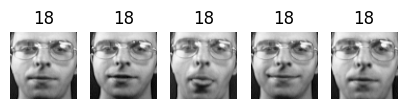

Cluster 17


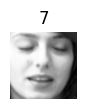

Cluster 18


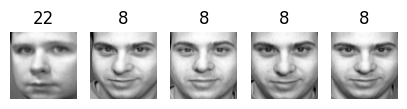

Cluster 19


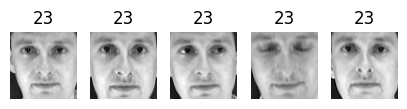

Cluster 20


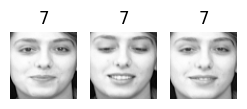

Cluster 21


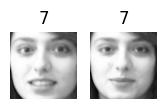

Cluster 22


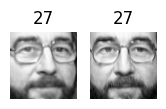

Cluster 23


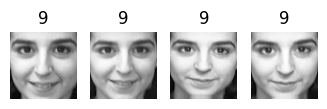

Cluster 24


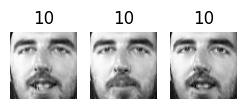

Cluster 25


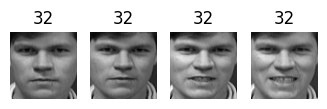

Cluster 26


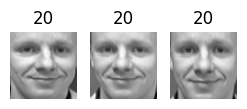

Cluster 27


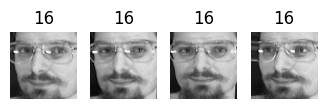

Cluster 28


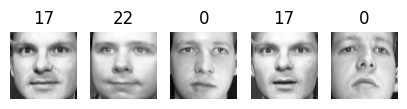

Cluster 29


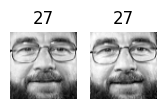

Cluster 30


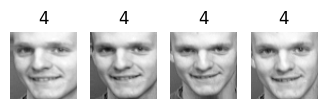

Cluster 31


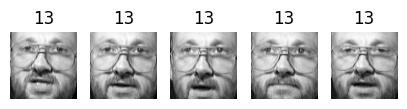

Cluster 32


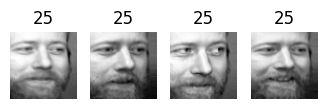

Cluster 33


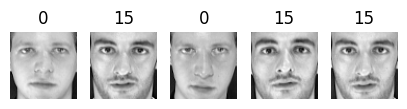

Cluster 34


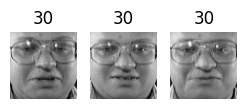

Cluster 35


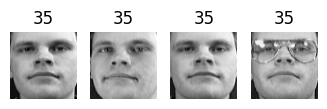

Cluster 36


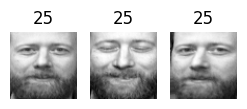

Cluster 37


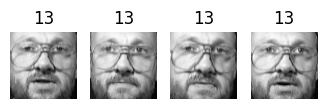

Cluster 38


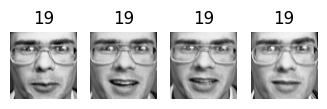

Cluster 39


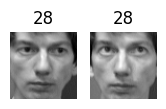

Cluster 40


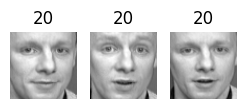

Cluster 41


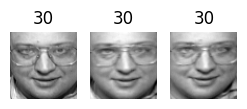

Cluster 42


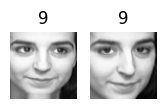

Cluster 43


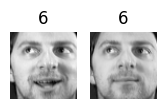

Cluster 44


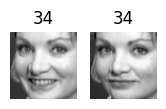

Cluster 45


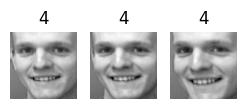

Cluster 46


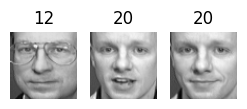

Cluster 47


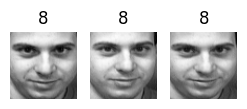

Cluster 48


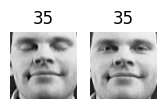

Cluster 49


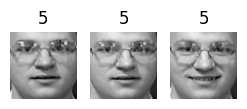

Cluster 50


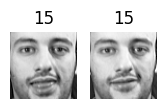

Cluster 51


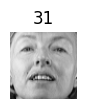

Cluster 52


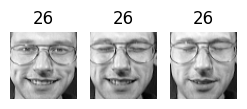

Cluster 53


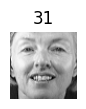

Cluster 54


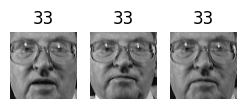

Cluster 55


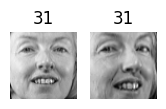

Cluster 56


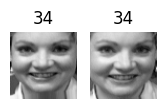

Cluster 57


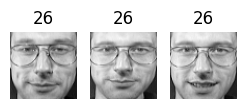

Cluster 58


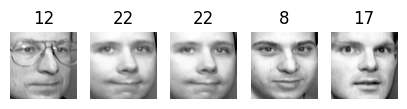

Cluster 59


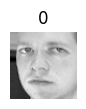

Cluster 60


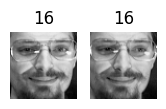

Cluster 61


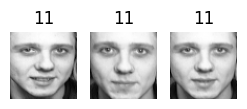

Cluster 62


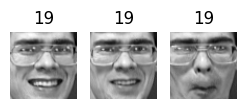

Cluster 63


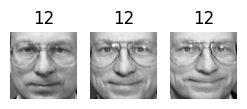

Cluster 64


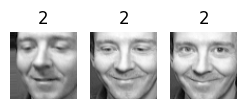

Cluster 65


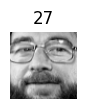

Cluster 66


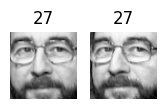

Cluster 67


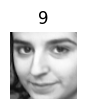

Cluster 68


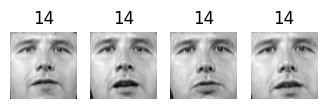

Cluster 69


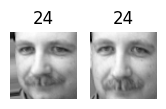

Cluster 70


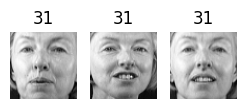

Cluster 71


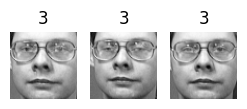

Cluster 72


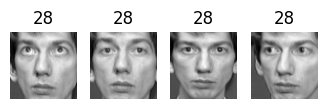

Cluster 73


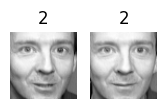

Cluster 74


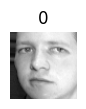

Cluster 75


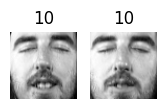

Cluster 76


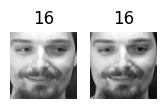

Cluster 77


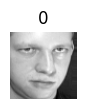

Cluster 78


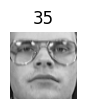

Cluster 79


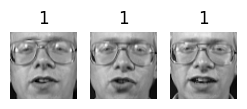

Cluster 80


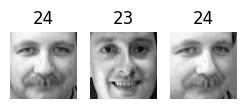

Cluster 81


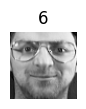

Cluster 82


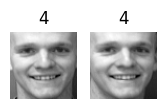

Cluster 83


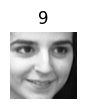

Cluster 84


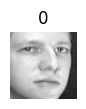

Cluster 85


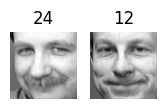

Cluster 86


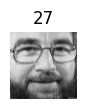

Cluster 87


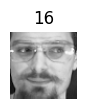

Cluster 88


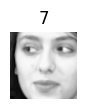

Cluster 89


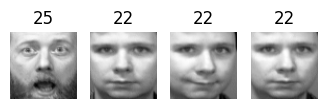

Cluster 90


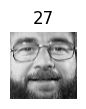

Cluster 91


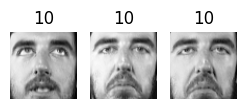

Cluster 92


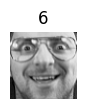

Cluster 93


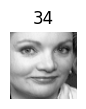

Cluster 94


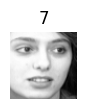

In [95]:
def plot_faces(faces, labels, n_cols=5):
    faces = faces.reshape(-1, 64, 64)
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows * 1.1))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray")
        plt.axis("off")
        plt.title(label)
    plt.show()

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans.fit(X_train, y_train)
for cluster_id in np.unique(kmeans.labels_):
    print("Cluster", cluster_id)
    in_cluster = (kmeans.labels_ == cluster_id)
    faces = X_train[in_cluster]
    labels = y_train[in_cluster]
    plot_faces(faces, labels)

In [96]:
len(np.unique(kmeans.labels_))

95

In [97]:
len(np.unique(y_train))

36

### ⑪

In [98]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train, y_train)

clf.score(X_valid, y_valid)

0.875

In [99]:
X_train_reduced = kmeans.transform(X_train)
X_valid_reduced = kmeans.transform(X_valid)
clf.fit(X_train_reduced, y_train)

clf.score(X_valid_reduced, y_valid)

0.725

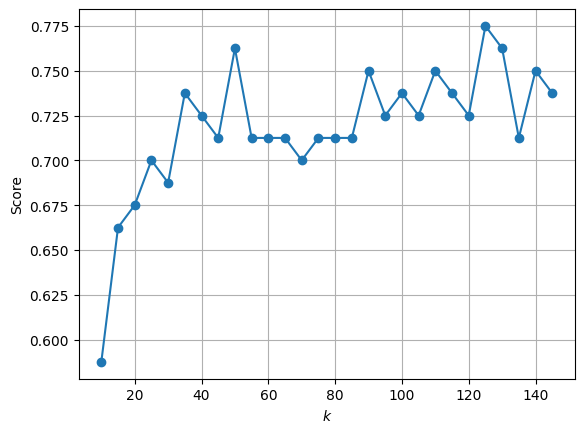

In [100]:
from sklearn.pipeline import make_pipeline

ks = range(10, 150, 5)
scores = []
for k in ks:
    pipeline = make_pipeline(
        KMeans(n_clusters=k, n_init=10, random_state=42),
        RandomForestClassifier(n_estimators=150, random_state=42)
    )
    
    pipeline.fit(X_train, y_train)
    scores.append(pipeline.score(X_valid, y_valid))

plt.plot(ks, scores, 'o-')
plt.grid()
plt.xlabel('$k$')
plt.ylabel('Score')
plt.show()

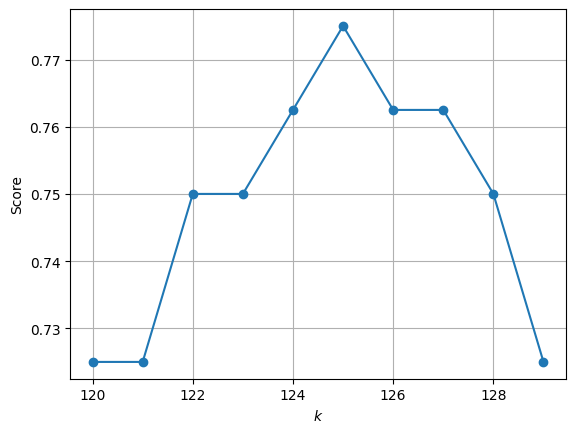

In [101]:
ks = range(120, 130)
scores = []
for k in ks:
    pipeline = make_pipeline(
        KMeans(n_clusters=k, n_init=10, random_state=42),
        RandomForestClassifier(n_estimators=150, random_state=42)
    )
    
    pipeline.fit(X_train, y_train)
    scores.append(pipeline.score(X_valid, y_valid))

plt.plot(ks, scores, 'o-')
plt.grid()
plt.xlabel('$k$')
plt.ylabel('Score')
plt.show()

In [102]:
best_k = ks[np.array(scores).argmax()]

best_k

125

In [103]:
max(scores)

0.775

In [104]:
X_train_extended = np.c_[X_train, X_train_reduced]
X_valid_extended = np.c_[X_valid, X_valid_reduced]

In [105]:
clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_extended, y_train)

clf.score(X_valid_extended, y_valid)

0.875

### ⑫

In [106]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.99)
X_train_pca = pca.fit_transform(X_train)
X_valid_pca = pca.transform(X_valid)

In [107]:
X_train_pca.shape

(280, 198)

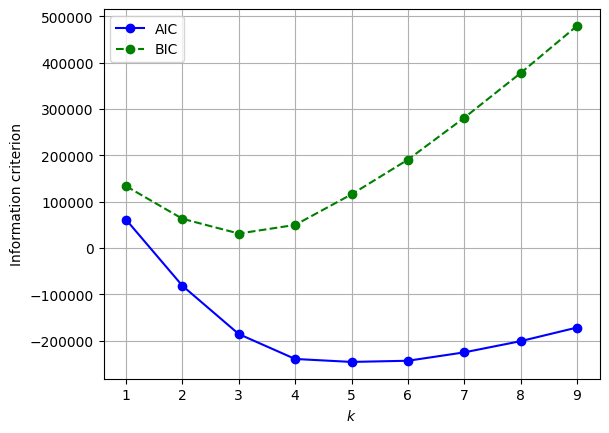

In [108]:
aics, bics = [], []
ks = range(1, 10)
for k in ks:
    gm_ = GaussianMixture(n_components=k, n_init=10, random_state=42)
    gm_.fit(X_train_pca)
    aics.append(gm_.aic(X_train_pca))
    bics.append(gm_.bic(X_train_pca))

plt.plot(ks, aics, 'bo-', label='AIC')
plt.plot(ks, bics, 'go--', label='BIC')
plt.legend()
plt.grid()
plt.xlabel('$k$')
plt.ylabel('Information criterion')
plt.show()

In [109]:
gm = GaussianMixture(n_components=4, n_init=10, random_state=42)
gm.fit(X_train_pca, y_train)

,"n_components n_components: int, default=1The number of mixture components.",4
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",10
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [110]:
n_gen_faces = 20
gen_faces_reduced, y_gen_faces = gm.sample(n_samples=n_gen_faces)
gen_faces = pca.inverse_transform(gen_faces_reduced)

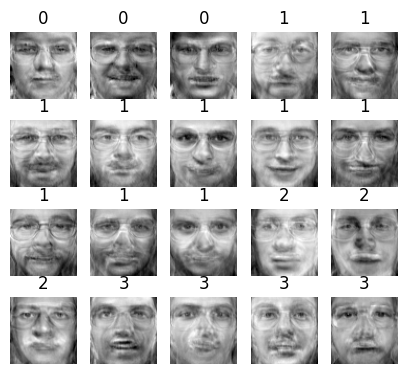

In [111]:
plot_faces(gen_faces, y_gen_faces)

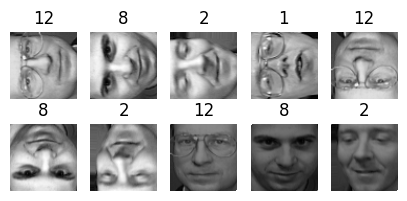

In [112]:
n_rotated = 4
rotated = np.transpose(X_train[:n_rotated].reshape(-1, 64, 64), axes=[0, 2, 1])
rotated = rotated.reshape(-1, 64*64)
y_rotated = y_train[:n_rotated]

n_flipped = 3
flipped = X_train[:n_flipped].reshape(-1, 64, 64)[:, ::-1]
flipped = flipped.reshape(-1, 64*64)
y_flipped = y_train[:n_flipped]

n_darkened = 3
darkened = X_train[:n_darkened].copy()
darkened[:, 1:-1] *= 0.3
y_darkened = y_train[:n_darkened]

X_bad_faces = np.r_[rotated, flipped, darkened]
y_bad = np.concatenate([y_rotated, y_flipped, y_darkened])

plot_faces(X_bad_faces, y_bad)

In [113]:
X_bad_faces_pca = pca.transform(X_bad_faces)
gm.score_samples(X_bad_faces_pca)

array([-1.4871938e+07, -1.3806046e+07, -1.5756331e+07, -1.2014358e+07,
       -8.5477680e+06, -1.4113451e+07, -1.2146042e+07, -1.2816146e+07,
       -1.5580996e+07, -1.6098318e+07], dtype=float32)

In [114]:
gm.score_samples(X_train_pca[:10])

array([691.7054 , 648.20435, 814.56335, 728.1952 , 648.20294, 728.1951 ,
       728.19543, 728.19617, 691.7055 , 814.56396], dtype=float32)

### ⑬

In [115]:
from sklearn.metrics import root_mean_squared_error

def reconstruction_errors(pca, X):
    X_pca = pca.transform(X)
    X_reconstruction = pca.inverse_transform(X_pca)
    rmse = np.array([root_mean_squared_error(X[i], X_reconstruction[i]) for i in range(len(X))])
    return rmse

In [116]:
reconstruction_errors(pca, X_train).mean()

np.float64(0.012867294908833824)

In [117]:
reconstruction_errors(pca, X_bad_faces).mean()

np.float64(0.0694552231580019)

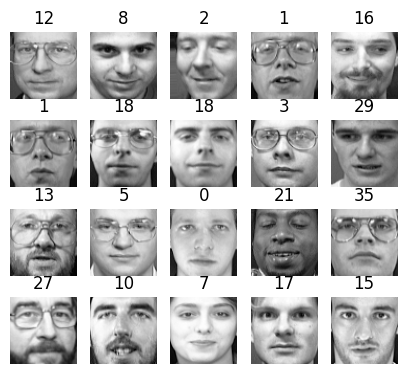

In [118]:
plot_faces(X_train[:20], y_train[:20])

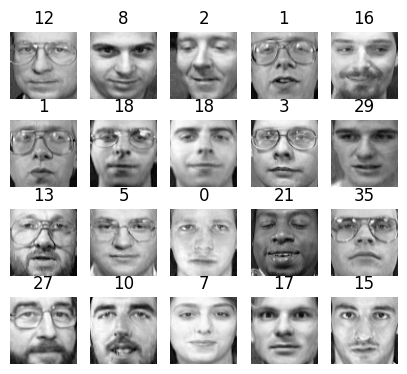

In [119]:
plot_faces(pca.inverse_transform(pca.transform(X_train[:20])), y_train[:20])

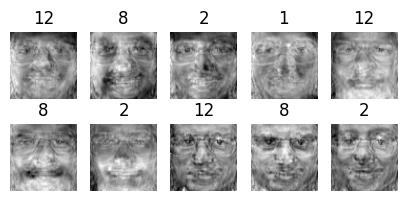

In [120]:
plot_faces(pca.inverse_transform(pca.transform(X_bad_faces)), y_bad)